*Author: Sunil Jain*  

**October 2026 Foster Care Visit Compliance & Risk Audit**
**Goal:** Determine whether children in out-of-home placement (foster care cohort) received required in-person caseworker visits during the target reporting month (Oct 2026) in compliance with federal Title IV-B standards (95% High-Risk Benchmark) and state SSA policy. Audit risk assessment validity and caseworker workload across LDSS jurisdictions with specific scrutiny on High-Risk cases.

**Deliverables Required**
1. Clean Dataset: Create a clean, analysis-ready dataset and document your technical process for data cleaning, relational merging, deduplication, and aggregation logic. 
2. Executive Briefing Memo (1–2 Pages): Create a written briefing addressed to the Director of Systems Operations and SSA Executive Leadership summarizing findings, compliance gaps by risk level and LDSS, and operational recommendations.

*Ground Rule: No use AI-LLM.* 
*Tool of choice: Jupyter Notebook/Python.*

In [1]:
# 1. Imports & Data Ingestion
import glob
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load raw CJAMS visit logs and SSA master child risk profiles
visits_raw = pd.read_excel("CJAMS_Casework_Visits_Oct2026_Raw.csv.xlsx")
risk_raw = pd.read_excel("SSA_Child_Risk_Profiles.csv.xlsx")

print("Starting Visit Rows:", len(visits_raw))
print("Starting Kid Profiles:", len(risk_raw))
display(visits_raw.head(3))
display(risk_raw.head(3))

Starting Visit Rows: 1200
Starting Kid Profiles: 400


,VISIT_ID,CHILD_ID,LDSS_JURISDICTION,VISIT_DATE,VISIT_TYPE,LOCATION_TYPE,PRIMARY_WORKER_ID,CASE_STATUS
0,V-80001,C-1001,BALT_CITY,2026-10-01,In-Person Foster Home,Residence,W-101,Active Foster Care
1,V-80002,C-1002,Baltimore City,2026-10-01,In-Person Foster Home,Residence,W-102,Active Foster Care
2,V-80003,C-1003,AA_COUNTY,2026-10-01,Virtual/Telehealth,Office,W-103,Active Foster Care


,CHILD_ID,SAFETY_RISK_LEVEL,PRIMARY_SAFETY_CONCERN,LAST_ASSESSMENT_DATE
0,C-1001,High,Severe Neglect,2025-03-14
1,C-1002,Moderate,Domestic Violence,2025-06-22
2,C-1003,Low,Emotional Abuse,2025-01-18


In [2]:
# 2. Schema Normalization, Jurisdiction Mapping & Deduplication

visits = visits_raw.copy()
risk = risk_raw.copy()

# 2.1. Clean column names
visits.columns = visits.columns.str.strip()
risk.columns = risk.columns.str.strip()

# 2.2. Normalize primary/foreign keys
visits['CHILD_ID'] = visits['CHILD_ID'].astype(str).str.strip().str.upper()
visits['VISIT_ID'] = visits['VISIT_ID'].astype(str).str.strip().str.upper()
risk['CHILD_ID'] = risk['CHILD_ID'].astype(str).str.strip().str.upper()

# 2.3. Standardize LDSS jurisdiction aliases into 4 canonical names
county_map = {
    'BALT_CITY': 'Baltimore City',
    'BALTIMORE CITY': 'Baltimore City',
    'AA_COUNTY': 'Anne Arundel',
    'ANNE ARUNDEL': 'Anne Arundel',
    'ANNE ARUNDEL COUNTY': 'Anne Arundel',
    'BALT_CO': 'Baltimore County',
    'BALT_COUNTY': 'Baltimore County',
    'BALTIMORE COUNTY': 'Baltimore County',
    'BALTIMORE CO.': 'Baltimore County',
    'PG_COUNTY': "Prince George's",
    "PRINCE GEORGE'S": "Prince George's",
    'PRINCE GEORGES': "Prince George's"
}
visits['COUNTY_CLEAN'] = (
    visits['LDSS_JURISDICTION']
    .astype(str)
    .str.strip()
    .str.upper()
    .map(county_map)
    .fillna(visits['LDSS_JURISDICTION'])
)

# 2.4. Parse dates
visits['VISIT_DATE_CLEAN'] = pd.to_datetime(visits['VISIT_DATE'], errors='coerce')
risk['LAST_ASSESSMENT_DATE'] = pd.to_datetime(risk['LAST_ASSESSMENT_DATE'], errors='coerce')

# 2.5. Deduplicate visit logs and child risk profiles
visits_dedup = visits.drop_duplicates(subset=['VISIT_ID']).copy()
risk_dedup = risk.drop_duplicates(subset=['CHILD_ID']).copy()

print(f"Date range in visits: {visits_dedup['VISIT_DATE_CLEAN'].min()} to {visits_dedup['VISIT_DATE_CLEAN'].max()}")
print(f"Removed {len(visits) - len(visits_dedup)} identical duplicate visits.")
print(f"Removed {len(risk) - len(risk_dedup)} duplicate child profiles.")
print("\nClean County Counts (All Deduplicated Logs):")
print(visits_dedup['COUNTY_CLEAN'].value_counts(dropna=False))

Date range in visits: 2026-10-01 00:00:00 to 2026-10-31 00:00:00
Removed 18 identical duplicate visits.
Removed 0 duplicate child profiles.

Clean County Counts (All Deduplicated Logs):
COUNTY_CLEAN
Baltimore City      298
Anne Arundel        298
Baltimore County    296
Prince George's     290
Name: count, dtype: int64


In [3]:
# 3. Reporting Window, Status Transitions & Visit Classification
# 3.1. Filter to target reporting window (October 1–31, 2026)
in_october = (
    (visits_dedup['VISIT_DATE_CLEAN'] >= '2026-10-01') &
    (visits_dedup['VISIT_DATE_CLEAN'] <= '2026-10-31')
)
visits_oct = visits_dedup[in_october].copy()
visits_oct['CASE_STATUS_CLEAN'] = visits_oct['CASE_STATUS'].astype(str).str.strip()

print("=== OCTOBER 2026 LOGS BY PLACEMENT STATUS ===")
print(visits_oct['CASE_STATUS_CLEAN'].value_counts(dropna=False))

# Check mid-month placement status transitions per child
status_per_child = visits_oct.groupby('CHILD_ID')['CASE_STATUS_CLEAN'].nunique()
transition_ids = status_per_child[status_per_child > 1].index.tolist()
print(f"Children with mid-October status transitions: {len(transition_ids)}")

# 3.2. Retain Active Foster Care logs for compliance numerator
is_active_oct = visits_oct['CASE_STATUS_CLEAN'].str.lower() == 'active foster care'
visits_oct_active = visits_oct[is_active_oct].copy()

# 3.3. Classify valid in-person visits vs. in-home residence visits
v_type = visits_oct_active['VISIT_TYPE'].astype(str).str.strip().str.lower()
l_type = visits_oct_active['LOCATION_TYPE'].astype(str).str.strip().str.lower()

visits_oct_active['IS_VALID_INPERSON'] = v_type.str.contains('in-person', na=False)
visits_oct_active['IS_IN_HOME'] = visits_oct_active['IS_VALID_INPERSON'] & (l_type == 'residence')

print("\n=== VISIT CLASSIFICATION BREAKDOWN (ACTIVE OCT 2026) ===")
print(visits_oct_active[['VISIT_TYPE', 'LOCATION_TYPE', 'IS_VALID_INPERSON', 'IS_IN_HOME']].value_counts())

=== OCTOBER 2026 LOGS BY PLACEMENT STATUS ===
CASE_STATUS_CLEAN
Active Foster Care    1104
Pending Transfer        61
Discharged              15
Name: count, dtype: int64
Children with mid-October status transitions: 70

=== VISIT CLASSIFICATION BREAKDOWN (ACTIVE OCT 2026) ===
VISIT_TYPE                LOCATION_TYPE  IS_VALID_INPERSON  IS_IN_HOME
In-Person Foster Home     Residence      True               True          615
In-Person School          Community      True               False         164
Attempted - Unsuccessful  Residence      False              False         159
Virtual/Telehealth        Office         False              False         155
                          Residence      False              False          11
Name: count, dtype: int64


In [4]:
# 4. Authoritative Cohort, Jurisdiction & Assessment Quality Tiers)
# 4.1. Resolve authoritative LDSS jurisdiction per child
# Priority A: Modal county in Active Oct logs (tie-broken by latest visit date)
# Priority B: Fallback to any Oct log (e.g., Pending Transfer / Discharged) to trace zero-active-log youth
active_jur = (
    visits_oct_active.sort_values('VISIT_DATE_CLEAN', ascending=False)
    .groupby('CHILD_ID')['COUNTY_CLEAN']
    .agg(lambda s: s.mode().iloc[0])
)
any_oct_jur = (
    visits_oct.sort_values('VISIT_DATE_CLEAN', ascending=False)
    .groupby('CHILD_ID')['COUNTY_CLEAN']
    .agg(lambda s: s.mode().iloc[0])
)

jur_per_child = visits_oct_active.groupby('CHILD_ID')['COUNTY_CLEAN'].nunique()
print(f"Active youth with >1 jurisdiction in Oct 2026: {(jur_per_child > 1).sum()}")

# 4.2. Aggregate child-level October contact metrics & primary worker
child_visits = visits_oct_active.groupby('CHILD_ID').agg(
    TOTAL_ACTIVE_LOGS=('VISIT_ID', 'count'),
    VALID_INPERSON_VISITS=('IS_VALID_INPERSON', 'sum'),
    IN_HOME_VISITS=('IS_IN_HOME', 'sum'),
    PRIMARY_WORKER_ID=(
        'PRIMARY_WORKER_ID',
        lambda s: s.dropna().mode().iloc[0] if not s.dropna().empty else np.nan
    )
).reset_index()

child_visits['MET_COMPLIANCE'] = child_visits['VALID_INPERSON_VISITS'] >= 1

# 4.3. Establish authoritative active cohort
# Exclude children confirmed solely as Discharged / Pending Transfer in October
active_ids = set(visits_oct_active['CHILD_ID'])
non_active_only_ids = set(visits_oct[~is_active_oct]['CHILD_ID']) - active_ids
print(f"Master Risk IDs confirmed non-active only in Oct 2026: {len(non_active_only_ids)}")

master_active = risk_dedup[~risk_dedup['CHILD_ID'].isin(non_active_only_ids)].copy()

# Left join visit summaries onto authoritative master risk table (preserves zero-log youth)
cohort = pd.merge(master_active, child_visits, on='CHILD_ID', how='left')
cohort['COUNTY'] = (
    cohort['CHILD_ID'].map(active_jur)
    .fillna(cohort['CHILD_ID'].map(any_oct_jur))
    .fillna('Unassigned (Zero Logs)')
)

cohort['TOTAL_ACTIVE_LOGS'] = cohort['TOTAL_ACTIVE_LOGS'].fillna(0).astype(int)
cohort['VALID_INPERSON_VISITS'] = cohort['VALID_INPERSON_VISITS'].fillna(0).astype(int)
cohort['IN_HOME_VISITS'] = cohort['IN_HOME_VISITS'].fillna(0).astype(int)
cohort['MET_COMPLIANCE'] = cohort['MET_COMPLIANCE'].fillna(False).astype(bool)
cohort['PRIMARY_WORKER_ID'] = (
    cohort['PRIMARY_WORKER_ID']
    .fillna('Unassigned (No Oct Logs)')
    .astype(str)
    .str.strip()
)

# 4.4. Separate Missing vs. Stale Risk Assessments (>180 days prior to Oct 31, 2026) & Missing Safety Concerns
risk_str = cohort['SAFETY_RISK_LEVEL'].fillna('Unassessed').astype(str).str.strip()
cohort['RISK_CLEAN'] = np.where(risk_str.isin(['', 'nan', 'None', 'Unassessed']), 'Unassessed', risk_str)

concern_str = cohort['PRIMARY_SAFETY_CONCERN'].fillna('Missing').astype(str).str.strip()
cohort['CONCERN_CLEAN'] = np.where(concern_str.isin(['', 'nan', 'None']), 'Missing', concern_str)

cutoff_stale = pd.Timestamp('2026-10-31') - pd.Timedelta(days=180)
cohort['ASSESSMENT_STATUS'] = np.select(
    [
        (cohort['RISK_CLEAN'] == 'Unassessed') | (cohort['LAST_ASSESSMENT_DATE'].isna()),
        cohort['LAST_ASSESSMENT_DATE'] < cutoff_stale
    ],
    [
        'Missing Risk Level / Date',
        'Stale (>180 Days Old)'
    ],
    default='Current (<=180 Days)'
)
cohort['MISSING_ASSESSMENT'] = cohort['ASSESSMENT_STATUS'] == 'Missing Risk Level / Date'

print("\n=== AUTHORITATIVE COHORT & ASSESSMENT VALIDITY SUMMARY ===")
print("Final Active Kids in Cohort:", len(cohort))
print("Kids in visit logs missing from Risk file:", len(active_ids - set(risk_dedup['CHILD_ID'])))
print("\nAssessment Validity Breakdown:")
print(cohort['ASSESSMENT_STATUS'].value_counts())
print("Missing Primary Safety Concern:", (cohort['CONCERN_CLEAN'] == 'Missing').sum())

Active youth with >1 jurisdiction in Oct 2026: 310
Master Risk IDs confirmed non-active only in Oct 2026: 0

=== AUTHORITATIVE COHORT & ASSESSMENT VALIDITY SUMMARY ===
Final Active Kids in Cohort: 400
Kids in visit logs missing from Risk file: 0

Assessment Validity Breakdown:
ASSESSMENT_STATUS
Stale (>180 Days Old)        325
Missing Risk Level / Date     46
Current (<=180 Days)          29
Name: count, dtype: int64
Missing Primary Safety Concern: 76


/var/folders/5g/_xx2dh7119q4gwkgghjqt7wr0000gn/T/ipykernel_16477/2522591163.py:51: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cohort['MET_COMPLIANCE'] = cohort['MET_COMPLIANCE'].fillna(False).astype(bool)
/var/folders/5g/_xx2dh7119q4gwkgghjqt7wr0000gn/T/ipykernel_16477/2522591163.py:66: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  cutoff_stale = pd.Timestamp('2026-10-31') - pd.Timedelta(days=180)


In [5]:
# 5. Research Questions 1–4 & Separated 4-Tier Risk/Dosage Tables

risk_order = ['High', 'Moderate', 'Low', 'Unassessed']

print("=== QUESTION 1: COHORT & ASSESSMENT VALIDITY ===")
print(f"Total Unique Active Children:       {len(cohort)}")
print(f"Missing Risk Level or Date:       {(cohort['ASSESSMENT_STATUS'] == 'Missing Risk Level / Date').sum()}")
print(f"Stale Assessment (>180 Days Old):   {(cohort['ASSESSMENT_STATUS'] == 'Stale (>180 Days Old)').sum()}")
print(f"Current Assessment (<=180 Days):    {(cohort['ASSESSMENT_STATUS'] == 'Current (<=180 Days)').sum()}")
print(f"Missing Primary Safety Concern:     {(cohort['CONCERN_CLEAN'] == 'Missing').sum()}")

print("\n=== QUESTION 2 & 4: COMPLIANCE & VISIT DOSAGE BY ALL 4 RISK TIERS (GOAL = 95% HIGH RISK) ===")
q2_q4 = cohort.groupby('RISK_CLEAN').agg(
    Kids=('CHILD_ID', 'count'),
    Compliant_Kids=('MET_COMPLIANCE', 'sum'),
    Compliance_Rate=('MET_COMPLIANCE', lambda x: round(x.mean() * 100, 1)),
    Mean_Valid_Visits=('VALID_INPERSON_VISITS', lambda x: round(x.mean(), 2)),
    Median_Valid_Visits=('VALID_INPERSON_VISITS', 'median'),
    In_Home_Share_Pct=('IN_HOME_VISITS', lambda x: round(
        (x.sum() / max(cohort.loc[x.index, 'VALID_INPERSON_VISITS'].sum(), 1)) * 100, 1
    ))
).reindex(risk_order)
display(q2_q4)

print("\n=== QUESTION 3A: COMPLIANCE BY COUNTY & RISK LEVEL (%) ===")
q3_cross = pd.crosstab(
    cohort['COUNTY'],
    cohort['RISK_CLEAN'],
    values=cohort['MET_COMPLIANCE'],
    aggfunc=lambda x: round(x.mean() * 100, 1)
).reindex(columns=risk_order)
display(q3_cross)

print("\n=== QUESTION 3B: HIGH-RISK VISIT LOCATIONS (RESIDENCE VS. COMMUNITY/OFFICE) ===")
hr_visits = visits_oct_active[
    (visits_oct_active['CHILD_ID'].isin(cohort[cohort['RISK_CLEAN'] == 'High']['CHILD_ID'])) &
    (visits_oct_active['IS_VALID_INPERSON'])
]
print(hr_visits['LOCATION_TYPE'].value_counts(normalize=True).mul(100).round(1))

# Q3B Explicit 3-category reindex (Residence, Community, Office)
loc_dist = (
    hr_visits['LOCATION_TYPE']
    .str.strip()
    .value_counts(normalize=True)
    .reindex(['Residence', 'Community', 'Office'], fill_value=0.0)
    .mul(100)
    .round(1)
)
print("\n=== QUESTION 3B (EXACT 3-SETTING BREAKDOWN) ===")
print(loc_dist)

# Q4 Pooled Low/Moderate-Risk vs. High-Risk comparison
cohort['RISK_BINARY'] = np.where(
    cohort['RISK_CLEAN'] == 'High', 'High-Risk',
    np.where(cohort['RISK_CLEAN'].isin(['Low', 'Moderate']), 'Low/Moderate-Risk', 'Unassessed')
)
q4_pooled = cohort.groupby('RISK_BINARY').agg(
    Kids=('CHILD_ID', 'count'),
    Mean_Valid_Visits=('VALID_INPERSON_VISITS', lambda x: round(x.mean(), 2)),
    Median_Valid_Visits=('VALID_INPERSON_VISITS', 'median')
).reindex(['High-Risk', 'Low/Moderate-Risk', 'Unassessed'])
print("\n=== QUESTION 4 (POOLED LOW/MODERATE COMPARISON) ===")
display(q4_pooled)

=== QUESTION 1: COHORT & ASSESSMENT VALIDITY ===
Total Unique Active Children:       400
Missing Risk Level or Date:       46
Stale Assessment (>180 Days Old):   325
Current Assessment (<=180 Days):    29
Missing Primary Safety Concern:     76

=== QUESTION 2 & 4: COMPLIANCE & VISIT DOSAGE BY ALL 4 RISK TIERS (GOAL = 95% HIGH RISK) ===


,Kids,Compliant_Kids,Compliance_Rate,Mean_Valid_Visits,Median_Valid_Visits,In_Home_Share_Pct
RISK_CLEAN,,,,,,
High,99,94,94.9,1.94,2.0,77.1
Moderate,158,147,93.0,1.94,2.0,76.9
Low,97,90,92.8,1.97,2.0,81.2
Unassessed,46,44,95.7,1.93,2.0,85.4



=== QUESTION 3A: COMPLIANCE BY COUNTY & RISK LEVEL (%) ===


RISK_CLEAN,High,Moderate,Low,Unassessed
COUNTY,,,,
Anne Arundel,100.0,98.5,97.1,100.0
Baltimore City,100.0,100.0,96.2,100.0
Baltimore County,100.0,92.3,100.0,100.0
Prince George's,100.0,100.0,100.0,100.0
Unassigned (Zero Logs),0.0,0.0,0.0,0.0



=== QUESTION 3B: HIGH-RISK VISIT LOCATIONS (RESIDENCE VS. COMMUNITY/OFFICE) ===
LOCATION_TYPE
Residence    77.1
Community    22.9
Name: proportion, dtype: float64

=== QUESTION 3B (EXACT 3-SETTING BREAKDOWN) ===
LOCATION_TYPE
Residence    77.1
Community    22.9
Office        0.0
Name: proportion, dtype: float64

=== QUESTION 4 (POOLED LOW/MODERATE COMPARISON) ===


,Kids,Mean_Valid_Visits,Median_Valid_Visits
RISK_BINARY,,,
High-Risk,99,1.94,2.0
Low/Moderate-Risk,255,1.95,2.0
Unassessed,46,1.93,2.0


,COUNTY,Total_Active_Children,High_Risk_Count,High_Risk_Compliance_Pct,Overall_Compliance_Pct,Pct_In_Home_Visits
0,Anne Arundel,144,26,100.0,98.6,76.9
1,Baltimore City,101,32,100.0,99.0,87.1
2,Baltimore County,78,23,100.0,97.4,67.3
3,Prince George's,57,13,100.0,100.0,86.2
4,Unassigned (Zero Logs),20,5,0.0,0.0,0.0


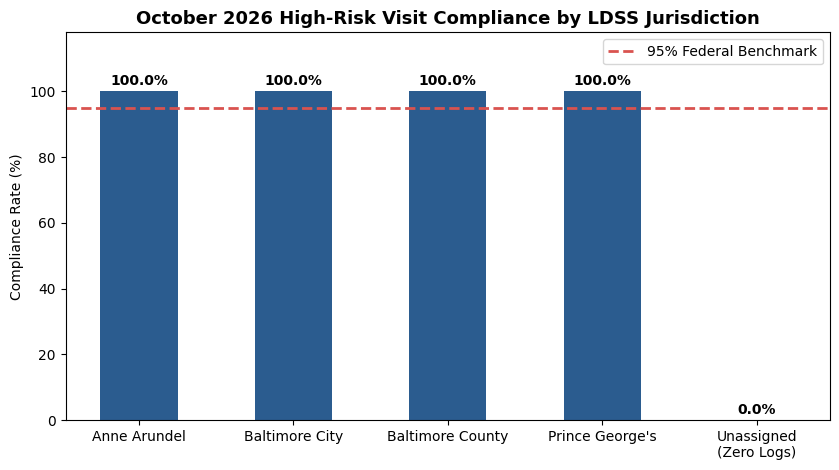

In [6]:
# 6.Executive Memo Risk Matrix & Jurisdictional Benchmark Chart
# 6.1 Executive Memo Summary Table
memo_table = cohort.groupby('COUNTY').agg(
    Total_Active_Children=('CHILD_ID', 'count'),
    High_Risk_Count=('RISK_CLEAN', lambda x: (x == 'High').sum()),
    High_Risk_Compliance_Pct=(
        'MET_COMPLIANCE',
        lambda x: round(x[cohort.loc[x.index, 'RISK_CLEAN'] == 'High'].mean() * 100, 1)
    ),
    Overall_Compliance_Pct=('MET_COMPLIANCE', lambda x: round(x.mean() * 100, 1)),
    Pct_In_Home_Visits=(
        'IN_HOME_VISITS',
        lambda x: round((x.sum() / max(cohort.loc[x.index, 'VALID_INPERSON_VISITS'].sum(), 1)) * 100, 1)
    )
).reset_index()

display(memo_table)

# 6.2 Bar Chart comparing High-Risk Compliance against the 95% Federal Benchmark
plt.figure(figsize=(8.5, 4.8))
labels = [c.replace(' (Zero Logs)', '\n(Zero Logs)') for c in memo_table['COUNTY']]
colors = ['#c0392b' if val < 95 else '#2b5c8f' for val in memo_table['High_Risk_Compliance_Pct']]

bars = plt.bar(labels, memo_table['High_Risk_Compliance_Pct'], color=colors, width=0.5)
plt.axhline(95, color='#d9534f', linestyle='--', linewidth=2, label='95% Federal Benchmark')
plt.title('October 2026 High-Risk Visit Compliance by LDSS Jurisdiction', fontsize=13, fontweight='bold')
plt.ylabel('Compliance Rate (%)')
plt.ylim(0, 118)
plt.legend(loc='upper right')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 2, f"{yval}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('High_Risk_Compliance_Chart_Final.png', dpi=300)
plt.show()

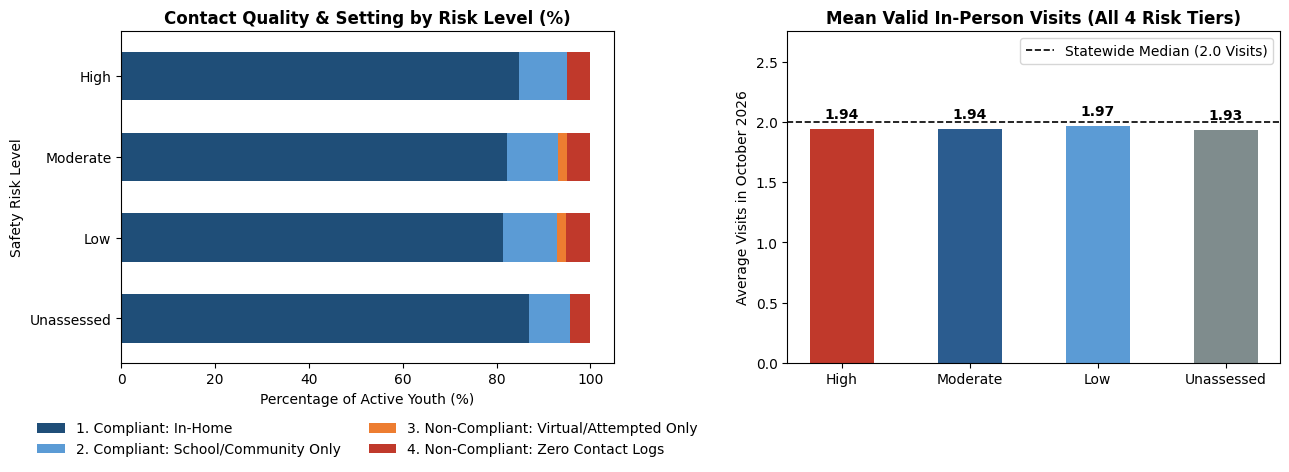

In [7]:
# 7. Contact Quality & Separated 4-Tier Visit Dosage Visuals
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- CHART A: Contact Quality & Setting Breakdown by Risk Tier ---
def classify_status(row):
    if row['IN_HOME_VISITS'] >= 1:
        return '1. Compliant: In-Home'
    elif row['VALID_INPERSON_VISITS'] >= 1:
        return '2. Compliant: School/Community Only'
    elif row['TOTAL_ACTIVE_LOGS'] > 0:
        return '3. Non-Compliant: Virtual/Attempted Only'
    else:
        return '4. Non-Compliant: Zero Contact Logs'

cohort['CONTACT_TIER'] = cohort.apply(classify_status, axis=1)
ct = pd.crosstab(cohort['RISK_CLEAN'], cohort['CONTACT_TIER'], normalize='index').mul(100).reindex(risk_order)

colors_a = ['#1f4e78', '#5b9bd5', '#ed7d31', '#c0392b']
ct.plot(kind='barh', stacked=True, ax=axes[0], color=colors_a, width=0.6)
axes[0].set_title('Contact Quality & Setting by Risk Level (%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Percentage of Active Youth (%)')
axes[0].set_ylabel('Safety Risk Level')
axes[0].legend(loc='lower center', bbox_to_anchor=(0.5, -0.32), ncol=2, frameon=False)
axes[0].invert_yaxis()

# --- CHART B: Separated 4-Tier Visit Dosage Parity ---
dosage = cohort.groupby('RISK_CLEAN')['VALID_INPERSON_VISITS'].mean().reindex(risk_order)
bars = axes[1].bar(dosage.index, dosage.values, color=['#c0392b', '#2b5c8f', '#5b9bd5', '#7f8c8d'], width=0.5)
axes[1].axhline(2.0, color='black', linestyle='--', linewidth=1.2, label='Statewide Median (2.0 Visits)')
axes[1].set_title('Mean Valid In-Person Visits (All 4 Risk Tiers)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Average Visits in October 2026')
axes[1].set_ylim(0, 2.75)
axes[1].legend(loc='upper right')

for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 0.09, f"{yval:.2f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('Inside_Story_Visuals.png', dpi=300, bbox_inches='tight')
plt.show()

,PRIMARY_WORKER_ID,Assigned_Kids,High_Risk_Kids,Compliant_Kids,Compliance_Pct,Valid_Visits,In_Home_Visits,Pct_In_Home
1,W-101,23,8,23,100.0,54,52,96.3
6,W-106,24,7,24,100.0,50,30,60.0
16,W-116,14,7,14,100.0,28,19,67.9
3,W-103,23,6,22,95.7,48,46,95.8
4,W-104,21,6,21,100.0,43,23,53.5
20,W-120,14,6,14,100.0,29,17,58.6
2,W-102,23,5,23,100.0,46,29,63.0
0,Unassigned (No Oct Logs),20,5,0,0.0,0,0,0.0
14,W-114,19,5,19,100.0,40,25,62.5
13,W-113,15,5,15,100.0,34,33,97.1


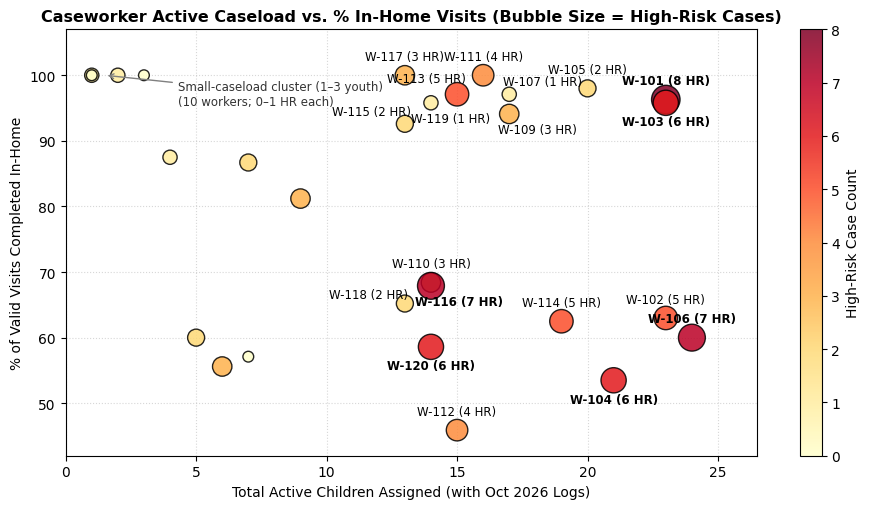

In [8]:
# 8. Reproducible Caseworker Workload & Caseload Scatter Plot
# 8.1. Aggregate caseworker-level metrics reproducibly from cohort
worker_summary = cohort.groupby('PRIMARY_WORKER_ID').agg(
    Assigned_Kids=('CHILD_ID', 'count'),
    High_Risk_Kids=('RISK_CLEAN', lambda x: (x == 'High').sum()),
    Compliant_Kids=('MET_COMPLIANCE', 'sum'),
    Compliance_Pct=('MET_COMPLIANCE', lambda x: round(x.mean() * 100, 1)),
    Valid_Visits=('VALID_INPERSON_VISITS', 'sum'),
    In_Home_Visits=('IN_HOME_VISITS', 'sum')
).reset_index()

worker_summary['Pct_In_Home'] = np.where(
    worker_summary['Valid_Visits'] > 0,
    (worker_summary['In_Home_Visits'] / worker_summary['Valid_Visits'] * 100).round(1),
    0.0
)

display(worker_summary.sort_values(by=['High_Risk_Kids', 'Assigned_Kids'], ascending=False))

# 8.2. Clean Caseworker Scatter Plot (Excluding Unassigned Zero-Log Bucket)
assigned_workers = worker_summary[worker_summary['PRIMARY_WORKER_ID'] != 'Unassigned (No Oct Logs)']

plt.figure(figsize=(9.5, 5.2))
scatter = plt.scatter(
    assigned_workers['Assigned_Kids'],
    assigned_workers['Pct_In_Home'],
    s=assigned_workers['High_Risk_Kids'] * 45 + 60,
    c=assigned_workers['High_Risk_Kids'],
    cmap='YlOrRd',
    edgecolors='black',
    alpha=0.85,
    zorder=3
)
plt.colorbar(scatter, label='High-Risk Case Count')

# Explicit (dx, dy) offsets in points to guarantee zero label collisions
label_offsets = {
    'W-101': (0, 11),
    'W-103': (0, -16),
    'W-113': (-22, 9),
    'W-107': (24, 7),
    'W-111': (0, 11),
    'W-117': (0, 11),
    'W-115': (-24, 6),
    'W-119': (14, -14),
    'W-109': (20, -14),
    'W-105': (0, 11),
    'W-110': (0, 11),
    'W-118': (-26, 4),
    'W-116': (20, -14),
    'W-120': (0, -16),
    'W-112': (0, 11),
    'W-114': (0, 11),
    'W-104': (0, -16),
    'W-102': (0, 11),
    'W-106': (0, 11),
}

for _, r in assigned_workers.iterrows():
    wid = r['PRIMARY_WORKER_ID']
    if wid in label_offsets:
        dx, dy = label_offsets[wid]
        plt.annotate(
            f"{wid} ({int(r['High_Risk_Kids'])} HR)",
            (r['Assigned_Kids'], r['Pct_In_Home']),
            textcoords="offset points",
            xytext=(dx, dy),
            ha='center',
            fontsize=8.5,
            fontweight='bold' if r['High_Risk_Kids'] >= 6 else 'normal',
            zorder=4
        )

plt.annotate(
    "Small-caseload cluster (1–3 youth)\n(10 workers; 0–1 HR each)",
    xy=(1.5, 100),
    xytext=(4.3, 95.5),
    arrowprops=dict(arrowstyle="->", color="gray", lw=1),
    fontsize=8.5,
    color="#333333"
)

plt.title('Caseworker Active Caseload vs. % In-Home Visits (Bubble Size = High-Risk Cases)', fontsize=11.5, fontweight='bold')
plt.xlabel('Total Active Children Assigned (with Oct 2026 Logs)')
plt.ylabel('% of Valid Visits Completed In-Home')
plt.xlim(0, 26.5)
plt.ylim(42, 107)
plt.grid(True, linestyle=':', alpha=0.5, zorder=0)
plt.tight_layout()
plt.savefig('Worker_Caseload_Analysis_Clean.png', dpi=300)
plt.show()

In [9]:
# 9. Statewide Verification & Accurate Waterfall Reconciliation Audit
# 9.1. Verify Statewide Totals for Table 1
total_active = len(cohort)
total_hr = (cohort['RISK_CLEAN'] == 'High').sum()
hr_comp_pct = round(cohort.loc[cohort['RISK_CLEAN'] == 'High', 'MET_COMPLIANCE'].mean() * 100, 1)
overall_comp_pct = round(cohort['MET_COMPLIANCE'].mean() * 100, 1)

total_in_home = int(cohort['IN_HOME_VISITS'].sum())
total_valid = int(cohort['VALID_INPERSON_VISITS'].sum())
in_home_pct = round((total_in_home / max(total_valid, 1)) * 100, 1)

print("=== TABLE 1 STATEWIDE TOTALS VERIFICATION ===")
print(f"Total Active Children:    {total_active}")
print(f"High-Risk Child Count:    {total_hr}")
print(f"High-Risk Compliance %:   {hr_comp_pct}% ({cohort.loc[cohort['RISK_CLEAN'] == 'High', 'MET_COMPLIANCE'].sum()}/{total_hr})")
print(f"Overall Compliance %:     {overall_comp_pct}% ({cohort['MET_COMPLIANCE'].sum()}/{total_active})")
print(f"% In-Home Visits:         {in_home_pct}% ({total_in_home}/{total_valid})")

# 9.2. Build Exact Dynamic Reconciliation Waterfall Table
non_oct_count = len(visits_dedup) - len(visits_oct)
non_active_oct_count = len(visits_oct) - len(visits_oct_active)
virtual_count = (visits_oct_active['VISIT_TYPE'].str.strip().str.lower() == 'virtual/telehealth').sum()
attempted_count = (visits_oct_active['VISIT_TYPE'].str.strip().str.lower() == 'attempted - unsuccessful').sum()
zero_log_count = (cohort['TOTAL_ACTIVE_LOGS'] == 0).sum()

audit_log = pd.DataFrame([
    {"Step": "1. Raw CJAMS Visit Log Rows", "Count": len(visits_raw), "Notes": "Raw Oct 2026 extract"},
    {"Step": "2. Deduplicated Visit Rows", "Count": len(visits_dedup), "Notes": f"Removed {len(visits_raw) - len(visits_dedup)} identical duplicate VISIT_ID rows"},
    {"Step": "3. October 2026 Visit Rows", "Count": len(visits_oct), "Notes": f"Excluded {non_oct_count} out-of-window rows"},
    {"Step": "4. Active Foster Care Oct Logs", "Count": len(visits_oct_active), "Notes": f"Excluded {non_active_oct_count} Pending Transfer / Discharged Oct rows"},
    {"Step": "5. Valid In-Person Visits", "Count": total_valid, "Notes": f"Excluded {virtual_count} Virtual/Telehealth & {attempted_count} Attempted logs"},
    {"Step": "6. In-Home Foster Residence Visits", "Count": total_in_home, "Notes": f"Valid in-person visits at Residence ({in_home_pct}%)"},
    {"Step": "7. Authoritative Active Child Cohort", "Count": total_active, "Notes": f"Master Risk File minus {len(non_active_only_ids)} non-active IDs; includes {zero_log_count} zero-log youth"}
])

display(audit_log)

=== TABLE 1 STATEWIDE TOTALS VERIFICATION ===
Total Active Children:    400
High-Risk Child Count:    99
High-Risk Compliance %:   94.9% (94/99)
Overall Compliance %:     93.8% (375/400)
% In-Home Visits:         78.9% (615/779)


,Step,Count,Notes
0,1. Raw CJAMS Visit Log Rows,1200,Raw Oct 2026 extract
1,2. Deduplicated Visit Rows,1182,Removed 18 identical duplicate VISIT_ID rows
2,3. October 2026 Visit Rows,1180,Excluded 2 out-of-window rows
3,4. Active Foster Care Oct Logs,1104,Excluded 76 Pending Transfer / Discharged Oct ...
4,5. Valid In-Person Visits,779,Excluded 166 Virtual/Telehealth & 159 Attempte...
5,6. In-Home Foster Residence Visits,615,Valid in-person visits at Residence (78.9%)
6,7. Authoritative Active Child Cohort,400,Master Risk File minus 0 non-active IDs; inclu...


In [10]:
# 10. Complete Multi-Tab Excel Deliverable Export
with pd.ExcelWriter("CJAMS_Clean_Deliverable_Oct2026.xlsx", engine="openpyxl") as writer:
    cohort.to_excel(writer, sheet_name="1_Final_Child_Cohort", index=False)
    visits_oct_active.to_excel(writer, sheet_name="2_Cleaned_Oct2026_Visits", index=False)
    memo_table.to_excel(writer, sheet_name="3_Executive_Summary_Table", index=False)
    q2_q4.reset_index().to_excel(writer, sheet_name="4_Risk_Compliance_Dosage", index=False)
    worker_summary.to_excel(writer, sheet_name="5_Caseworker_Workload", index=False)
    audit_log.to_excel(writer, sheet_name="6_Reconciliation_Waterfall", index=False)

print("Saved CJAMS_Clean_Deliverable_Oct2026.xlsx (6 sheets) and all 3 PNG charts successfully!")

Saved CJAMS_Clean_Deliverable_Oct2026.xlsx (6 sheets) and all 3 PNG charts successfully!


In [11]:
# 11. Export Complete HTML Report
notebooks = glob.glob("*.ipynb")
print("Found notebooks:", notebooks)

if notebooks:
    nb_file = notebooks[0]
    subprocess.run(["jupyter", "nbconvert", "--to", "html", nb_file], check=True)
    print(f"Exported {nb_file.replace('.ipynb', '.html')} successfully!")

Found notebooks: ['CJAMS_Analysis.ipynb']


[NbConvertApp] Converting notebook CJAMS_Analysis.ipynb to html


Exported CJAMS_Analysis.html successfully!


[NbConvertApp] WARNING | Alternative text is missing on 3 image(s).
[NbConvertApp] Writing 631823 bytes to CJAMS_Analysis.html


In [12]:
logged_non_compliant = cohort[(~cohort['MET_COMPLIANCE']) & (cohort['TOTAL_ACTIVE_LOGS'] > 0)][
    ['CHILD_ID', 'COUNTY', 'RISK_CLEAN', 'PRIMARY_WORKER_ID', 'TOTAL_ACTIVE_LOGS']
]
display(logged_non_compliant)

,CHILD_ID,COUNTY,RISK_CLEAN,PRIMARY_WORKER_ID,TOTAL_ACTIVE_LOGS
2,C-1003,Anne Arundel,Low,W-103,3
200,C-1201,Anne Arundel,Moderate,W-107,2
230,C-1231,Baltimore City,Low,W-111,3
293,C-1294,Baltimore County,Moderate,W-124,3
379,C-1380,Baltimore County,Moderate,W-110,2
